# Atividade 01 — Caracterização e exploração dos dados

Projeto da disciplina Sistemas Inteligentes Orientados a Dados (PGCOMP/UFBA, 2026.2).

O projeto trata das pendências socioambientais que impedem produtores rurais de vender para compradores sujeitos à regulação europeia antidesmatamento (EUDR) e de acessar crédito rural: embargo ambiental, desmatamento após 31/12/2020 e inclusão no Cadastro de Empregadores ("Lista Suja"). Este caderno verifica se os dados públicos necessários existem, em que estado estão e o que falta.

- **Fonte principal:** Áreas Embargadas do IBAMA.
- **Fontes complementares:** alertas de desmatamento do INPE (DETER/PRODES), Lista Suja do MTE e indicadores de preço do CEPEA.

**Como executar:** rode as partes em ordem. As partes 1 e 7 precisam de internet. O arquivo do IBAMA (~150 MB) é salvo em `data/raw/`, que não é versionado. Nenhuma saída exibe CPF, CNPJ ou nome de pessoa.

O resumo dos resultados está em [`docs/atividade-01-dados.md`](../docs/atividade-01-dados.md).

## Parte 0 — Configuração

In [1]:
import hashlib
import json
import logging
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)
try:
    import structlog  # usado internamente pela biblioteca agrobr
    structlog.configure(wrapper_class=structlog.make_filtering_bound_logger(logging.CRITICAL))
except ImportError:
    pass

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS = RAIZ / "data" / "raw"
DADOS.mkdir(parents=True, exist_ok=True)

DATA_CORTE_EUDR = pd.Timestamp("2020-12-31 23:59:59")
HOJE = pd.Timestamp.today()
print("pandas", pd.__version__, "| execução em", HOJE.strftime("%d/%m/%Y %H:%M"))

pandas 3.0.5 | execução em 13/09/2026 13:37


## Parte 1 — Obtenção da fonte principal

O IBAMA publica a base completa de termos de embargo em um único CSV, sem autenticação. O arquivo é baixado uma vez e reaproveitado. O hash SHA-256 e o cabeçalho HTTP registram exatamente qual versão foi analisada.

In [2]:
URL_EMBARGOS = "https://servicos.ibama.gov.br/ctf/publico/areasembargadas/arquivos/areas_embargadas.csv"
ARQ_EMBARGOS = DADOS / "areas_embargadas.csv"
ARQ_META = DADOS / "areas_embargadas.meta.json"

if not ARQ_EMBARGOS.exists():
    with requests.get(URL_EMBARGOS, stream=True, timeout=600) as r:
        r.raise_for_status()
        cabecalho = {k: r.headers.get(k) for k in ["Content-Type", "Last-Modified", "Content-Length"]}
        with open(ARQ_EMBARGOS, "wb") as f:
            for bloco in r.iter_content(chunk_size=1 << 20):
                f.write(bloco)
    ARQ_META.write_text(json.dumps({
        "url": URL_EMBARGOS,
        "baixado_em_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "cabecalho_http": cabecalho,
        "sha256": hashlib.sha256(ARQ_EMBARGOS.read_bytes()).hexdigest(),
    }, indent=2))

meta = json.loads(ARQ_META.read_text())
meta["tamanho_mb"] = round(ARQ_EMBARGOS.stat().st_size / 1e6, 1)
meta

{'url': 'https://servicos.ibama.gov.br/ctf/publico/areasembargadas/arquivos/areas_embargadas.csv',
 'baixado_em_utc': '2026-09-13T16:31:45+00:00',
 'cabecalho_http': {'Content-Type': 'text/csv',
  'Last-Modified': 'Sat, 12 Sep 2026 22:38:28 GMT',
  'Content-Length': '147984427'},
 'sha256': '8eaf1ba8995d65dc9843b62ee33159bb375733309e36d84946efd6a510e4d322',
 'tamanho_mb': 148.0}

## Parte 2 — Leitura correta

Três cuidados são necessários para ler esta base sem corromper dados:

1. o separador é `;`;
2. o arquivo é UTF-8, mas o servidor não informa a codificação no cabeçalho, e a leitura como Latin-1 (padrão comum em planilhas) corrompe acentos;
3. o CPF/CNPJ precisa ser lido como texto.

In [3]:
ARQ_EMBARGOS.read_bytes().decode("utf-8")  # gera erro se o arquivo não for UTF-8 válido
print("Arquivo é UTF-8 válido: sim")
print("Content-Type informado pelo servidor:", meta["cabecalho_http"]["Content-Type"])

amostra = pd.read_csv(ARQ_EMBARGOS, sep=";", usecols=["NOM_MUNICIPIO_TAD"], nrows=5000, encoding="latin1")
errado = next(v for v in amostra["NOM_MUNICIPIO_TAD"].dropna() if "Ã" in v)
print("Nome de município lido como Latin-1:", errado)
print("O mesmo nome lido como UTF-8:       ", errado.encode("latin1").decode("utf-8"))

Arquivo é UTF-8 válido: sim
Content-Type informado pelo servidor: text/csv
Nome de município lido como Latin-1: ImaruÃ­
O mesmo nome lido como UTF-8:        Imaruí


Sem instrução de tipo, o pandas interpreta o CPF/CNPJ como número decimal. Isso apaga os zeros à esquerda e altera o tamanho do identificador, o que faz o cruzamento com outras bases falhar sem nenhum aviso.

In [4]:
doc_numerico = pd.read_csv(ARQ_EMBARGOS, sep=";", usecols=["CPF_CNPJ_EMBARGADO"], low_memory=False)["CPF_CNPJ_EMBARGADO"]
print("Tipo inferido sem instrução:", doc_numerico.dtype)

emb = pd.read_csv(
    ARQ_EMBARGOS, sep=";", encoding="utf-8", low_memory=False,
    dtype={"CPF_CNPJ_EMBARGADO": str, "NUM_TAD": str, "SER_TAD": str, "QTD_AREA_EMBARGADA": str},
)
doc = emb["CPF_CNPJ_EMBARGADO"].str.replace(r"\D", "", regex=True)
print(f"Identificadores que começam com zero: {doc.str.startswith('0').sum():,}")

pd.DataFrame({
    "lido como número": doc_numerico.dropna().astype("int64").astype(str).str.len().value_counts(),
    "lido como texto": doc.dropna().str.len().value_counts(),
}).fillna(0).astype(int).rename_axis("dígitos").sort_index()

Tipo inferido sem instrução: float64


Identificadores que começam com zero: 25,490


,lido como número,lido como texto
dígitos,,
1,6,0
6,5,0
7,31,0
8,322,0
9,3266,0
10,15609,0
11,51234,70425
12,308,0
13,5901,2


## Parte 3 — Dimensão e intervalo temporal

In [5]:
datas = pd.to_datetime(emb["DAT_EMBARGO"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
doc_valido = doc.str.len().isin([11, 14])

pd.Series({
    "registros": len(emb),
    "colunas": emb.shape[1],
    "com CPF/CNPJ preenchido": int(doc.notna().sum()),
    "CPF (11 dígitos)": int((doc.str.len() == 11).sum()),
    "CNPJ (14 dígitos)": int((doc.str.len() == 14).sum()),
    "responsáveis distintos": int(doc[doc_valido].nunique()),
    "municípios distintos": int(emb["COD_MUNICIPIO_TAD"].nunique()),
    "datas não interpretáveis": int(datas.isna().sum()),
    "embargo mais antigo": datas.min().strftime("%d/%m/%Y"),
    "maior data encontrada": datas.max().strftime("%d/%m/%Y"),
    "embargos após 31/12/2020": int((datas > DATA_CORTE_EUDR).sum()),
}).to_frame("valor")

,valor
registros,91197
colunas,36
com CPF/CNPJ preenchido,81965
CPF (11 dígitos),70425
CNPJ (14 dígitos),11538
responsáveis distintos,67460
municípios distintos,3793
datas não interpretáveis,0
embargo mais antigo,16/12/1987
maior data encontrada,25/09/2925


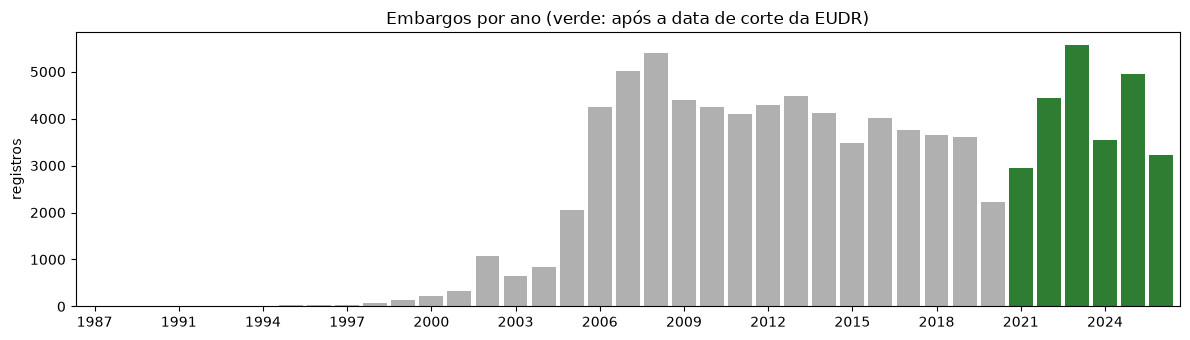

In [6]:
anos = datas[datas <= HOJE].dt.year.value_counts().sort_index()
cores = ["#b0b0b0" if a <= 2020 else "#2e7d32" for a in anos.index]
ax = anos.plot(kind="bar", figsize=(12, 3.5), color=cores, width=0.85)
ax.set_title("Embargos por ano (verde: após a data de corte da EUDR)")
ax.set_xlabel("")
ax.set_ylabel("registros")
ax.set_xticks(range(0, len(anos), 3))
ax.set_xticklabels(anos.index[::3], rotation=0)
plt.tight_layout()
plt.show()

## Parte 4 — Valores ausentes nos campos relevantes

Só os campos que o projeto usa para identificar o responsável, localizar a área e datar o embargo.

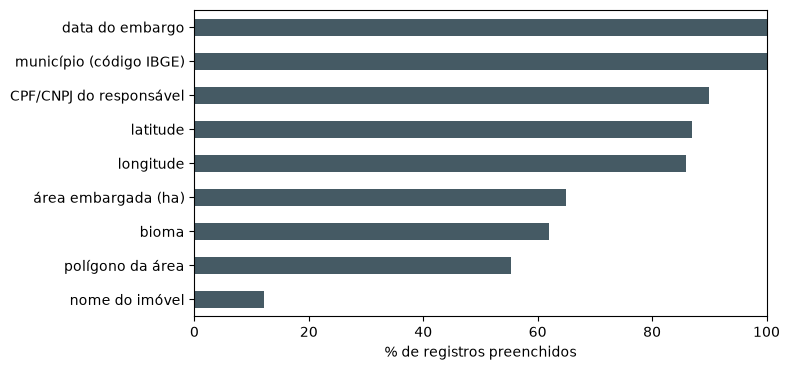

,campo,% preenchido
COD_MUNICIPIO_TAD,município (código IBGE),100.0
DAT_EMBARGO,data do embargo,100.0
CPF_CNPJ_EMBARGADO,CPF/CNPJ do responsável,89.9
NUM_LATITUDE_TAD,latitude,87.0
NUM_LONGITUDE_TAD,longitude,85.9
QTD_AREA_EMBARGADA,área embargada (ha),64.9
DES_TIPO_BIOMA,bioma,61.9
WKT_GEOM_AREA_EMBARGADA,polígono da área,55.4
NOME_IMOVEL,nome do imóvel,12.2


In [7]:
CAMPOS = {
    "COD_MUNICIPIO_TAD": "município (código IBGE)",
    "DAT_EMBARGO": "data do embargo",
    "CPF_CNPJ_EMBARGADO": "CPF/CNPJ do responsável",
    "NUM_LATITUDE_TAD": "latitude",
    "NUM_LONGITUDE_TAD": "longitude",
    "QTD_AREA_EMBARGADA": "área embargada (ha)",
    "DES_TIPO_BIOMA": "bioma",
    "WKT_GEOM_AREA_EMBARGADA": "polígono da área",
    "NOME_IMOVEL": "nome do imóvel",
}
preenchido = (emb[list(CAMPOS)].notna().mean() * 100).round(1)
ausentes = pd.DataFrame({"campo": list(CAMPOS.values()), "% preenchido": preenchido.values}, index=list(CAMPOS))

ax = ausentes.set_index("campo")["% preenchido"].sort_values().plot(kind="barh", figsize=(8, 3.8), color="#455a64")
ax.set_xlim(0, 100)
ax.set_xlabel("% de registros preenchidos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
ausentes

## Parte 5 — Qualidade

### 5.1 Duplicidades

In [8]:
termo = emb["NUM_TAD"].fillna("?") + "-" + emb["SER_TAD"].fillna("?")
repetido = termo.duplicated(keep=False)
print(f"Linhas idênticas: {emb.duplicated().sum():,}")
print(f"Linhas que compartilham número e série de termo: {repetido.sum():,} ({termo[repetido].nunique():,} termos)")

variacao = emb[repetido].groupby(termo[repetido]).nunique(dropna=False)
(variacao > 1).mean().sort_values(ascending=False).head(6).mul(100).round(0).to_frame("% dos termos repetidos em que o campo muda")

Linhas idênticas: 0
Linhas que compartilham número e série de termo: 250 (105 termos)


,% dos termos repetidos em que o campo muda
SEQ_TAD,100.0
DAT_ULT_ALTER_GEOM,98.0
DAT_ULT_ALTERACAO,90.0
DES_TAD,89.0
DES_LOCALIZACAO_TAD,88.0
QTD_AREA_EMBARGADA,85.0


As linhas repetidas não são cópias: dentro do mesmo número de termo mudam data, área e coordenadas. Portanto, o número do termo sozinho não serve como identificador único.

A base também tem repetição dentro de um mesmo campo. O bioma aparece como lista de texto com itens repetidos:

In [9]:
bioma = emb["DES_TIPO_BIOMA"].dropna()
partes = bioma.str.split(",").map(lambda xs: [x.strip() for x in xs])
bioma[partes.map(lambda xs: len(xs) != len(set(xs)))].value_counts().head(8).to_frame("registros")

,registros
DES_TIPO_BIOMA,
"Amazonia, Amazonia",75
"Cerrado, Cerrado",22
"Mata Atlantica, Mata Atlantica",14
"Caatinga, Caatinga",8
"Cerrado, Cerrado, Amazonia",2
"Pantanal, Pantanal",2
"Cerrado, Amazonia, Amazonia",1


### 5.2 Categorias com grafias distintas

In [10]:
ACENTOS = {"Amazonia": "Amazônia", "Mata Atlantica": "Mata Atlântica"}
bioma_normalizado = partes.map(lambda xs: ", ".join(sorted({ACENTOS.get(x, x) for x in xs})))

print("Valores distintos no campo bioma:", bioma.nunique())
print("Após remover repetição, ordenar e acentuar:", bioma_normalizado.nunique())
bioma_normalizado.value_counts().head(8).to_frame("registros")

Valores distintos no campo bioma: 39
Após remover repetição, ordenar e acentuar: 32


,registros
DES_TIPO_BIOMA,
Amazônia,34897
Mata Atlântica,9305
Cerrado,5746
Caatinga,4290
Costeiro e Marinho,1333
Pampa,229
Pantanal,226
"Amazônia, Cerrado",89


### 5.3 Registros aparentemente incorretos

In [11]:
lat, lon = emb["NUM_LATITUDE_TAD"], emb["NUM_LONGITUDE_TAD"]
coord_zero = (lat == 0) & (lon == 0)
coord_fora = lat.notna() & lon.notna() & ~coord_zero & ~(lat.between(-34.5, 5.5) & lon.between(-74.5, -28.5))
area = pd.to_numeric(emb["QTD_AREA_EMBARGADA"].str.replace(",", ".", regex=False), errors="coerce")

pd.Series({
    "data de embargo no futuro": int((datas > HOJE).sum()),
    "coordenada (0, 0)": int(coord_zero.sum()),
    "coordenada fora do território brasileiro": int(coord_fora.sum()),
    "CPF/CNPJ com número de dígitos inválido": int((doc.notna() & ~doc_valido).sum()),
    "área embargada igual a zero ou negativa": int((area <= 0).sum()),
}).to_frame("registros")

,registros
data de embargo no futuro,1
"coordenada (0, 0)",3180
coordenada fora do território brasileiro,254
CPF/CNPJ com número de dígitos inválido,2
área embargada igual a zero ou negativa,406


In [12]:
print("Datas no futuro:", sorted(datas[datas > HOJE].dt.strftime("%d/%m/%Y").unique()))

Datas no futuro: ['25/09/2925']


### 5.4 Cobertura geográfica utilizável

Para a EUDR, o que importa é conseguir localizar a área. Esta tabela mostra quantos registros têm polígono, quantos têm só uma coordenada válida e quantos não têm nenhum dos dois.

In [13]:
geo = pd.DataFrame({
    "tem polígono": emb["WKT_GEOM_AREA_EMBARGADA"].notna(),
    "tem coordenada válida": lat.notna() & lon.notna() & ~coord_zero & ~coord_fora,
})
geo["nem polígono nem coordenada"] = ~(geo["tem polígono"] | geo["tem coordenada válida"])

pd.DataFrame({
    "toda a base (%)": geo.mean() * 100,
    "após 31/12/2020 (%)": geo[datas > DATA_CORTE_EUDR].mean() * 100,
}).round(1)

,toda a base (%),após 31/12/2020 (%)
tem polígono,55.4,77.4
tem coordenada válida,82.1,99.7
nem polígono nem coordenada,15.3,0.1


### 5.5 Campos relevantes que não existem na base

In [14]:
procurados = ["CAR", "CULTURA", "ATIVIDADE", "SUPRESS", "AUTORIZ"]
print("Colunas da base:", len(emb.columns))
print("Colunas relacionadas a CAR, cultura ou autorização de supressão:",
      [c for c in emb.columns if any(p in c.upper().split("_") or p in c.upper() for p in procurados)])

Colunas da base: 36
Colunas relacionadas a CAR, cultura ou autorização de supressão: []


## Parte 6 — Estatísticas do domínio

Embargos após a data de corte da EUDR, por UF: quantidade e área embargada.

In [15]:
recentes = emb[datas > DATA_CORTE_EUDR].assign(area_ha=area[datas > DATA_CORTE_EUDR])
por_uf = (recentes.groupby("SIG_UF_TAD")
          .agg(embargos=("SIG_UF_TAD", "size"), area_total_ha=("area_ha", "sum"), area_mediana_ha=("area_ha", "median"))
          .sort_values("embargos", ascending=False))
por_uf["% dos embargos"] = (por_uf["embargos"] / por_uf["embargos"].sum() * 100).round(1)
por_uf.round(1).head(10)

,embargos,area_total_ha,area_mediana_ha,% dos embargos
SIG_UF_TAD,,,,
PA,5503,833616.6,58.9,22.3
AM,4127,738396.4,72.0,16.7
RO,2858,231400.8,42.7,11.6
AC,1463,166623.9,27.0,5.9
MT,1364,238629.9,55.9,5.5
MG,1177,11113.6,10.9,4.8
RR,892,46538.7,23.9,3.6
CE,863,20958.6,3.1,3.5
BA,798,48847.2,23.9,3.2


## Parte 7 — Fontes complementares

Verificações de disponibilidade e de junção. Os resultados dependem da resposta dos serviços no momento da execução.

### 7.1 INPE — alertas DETER (serviço WFS)

O DETER publica alertas de desmatamento com geometria, data e código IBGE do município. Esse código é a chave de junção com a base do IBAMA.

Os alertas incluem degradação, corte seletivo e cicatriz de queimada, não só desmatamento. O cruzamento para a EUDR precisa filtrar por classe.

In [16]:
WFS_DETER = "https://terrabrasilis.dpi.inpe.br/geoserver/deter-amz/ows"
base = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeName": "deter-amz:deter_amz"}

def contar(params):
    r = requests.get(WFS_DETER, params={**base, "resultType": "hits", **params}, timeout=120)
    r.raise_for_status()
    return int(re.search(r'numberMatched="(\d+)"', r.text).group(1))

print(f"Alertas DETER Amazônia (total): {contar({}):,}")
print(f"Alertas desde 01/01/2021: {contar({'CQL_FILTER': "view_date>='2021-01-01'"}):,}")
print(f"Alertas desde 01/01/{HOJE.year}: {contar({'CQL_FILTER': f"view_date>='{HOJE.year}-01-01'"}):,}")

Alertas DETER Amazônia (total): 457,815


Alertas desde 01/01/2021: 259,934


Alertas desde 01/01/2026: 14,030


In [17]:
r = requests.get(WFS_DETER, params={
    **base, "outputFormat": "application/json", "count": 500, "sortBy": "view_date D",
    "propertyName": "view_date,classname,municipality,mun_geocod,uf,areamunkm",
}, timeout=180)
r.raise_for_status()
deter = pd.DataFrame([f["properties"] for f in r.json()["features"]])

municipios_ibama = set(emb["COD_MUNICIPIO_TAD"].astype(str))
deter["municipio_tem_embargo"] = deter["mun_geocod"].astype(str).isin(municipios_ibama)
print("Alerta mais recente:", deter["view_date"].max())
print(f"Dos {len(deter)} alertas mais recentes, {deter['municipio_tem_embargo'].mean():.0%} ocorreram em municípios que também têm embargos na base do IBAMA.")
deter["classname"].value_counts().to_frame("alertas na amostra")

Alerta mais recente: 2026-09-04
Dos 500 alertas mais recentes, 98% ocorreram em municípios que também têm embargos na base do IBAMA.


,alertas na amostra
classname,
DESMATAMENTO_CR,284
CICATRIZ_DE_QUEIMADA,81
DEGRADACAO,61
CS_DESORDENADO,45
CS_GEOMETRICO,16
MINERACAO,12
DESMATAMENTO_VEG,1


### 7.2 INPE — PRODES por bioma

O DETER cobre só a Amazônia e o Cerrado. Para os demais biomas, a referência é o PRODES (anual). Abaixo, as camadas de desmatamento anual publicadas no mesmo servidor.

In [18]:
cap = requests.get("https://terrabrasilis.dpi.inpe.br/geoserver/ows",
                   params={"service": "WFS", "version": "2.0.0", "request": "GetCapabilities"}, timeout=120).text
camadas = sorted(set(re.findall(r"<Name>([a-z0-9\-]+:[a-z_]*yearly_deforestation[a-z_0-9]*)</Name>", cap)))
camadas

['prodes-amazon-nb:yearly_deforestation_biome',
 'prodes-caatinga-nb:yearly_deforestation',
 'prodes-cerrado-nb:yearly_deforestation',
 'prodes-legal-amz:yearly_deforestation',
 'prodes-mata-atlantica-nb:yearly_deforestation',
 'prodes-pampa-nb:yearly_deforestation',
 'prodes-pantanal-nb:yearly_deforestation']

### 7.3 MTE — Cadastro de Empregadores (Lista Suja)

A lista oficial é publicada em PDF. A biblioteca `agrobr` extrai a tabela, mas a extração traz ruído, que precisa ser limpo antes de qualquer cruzamento.

In [19]:
from agrobr.sync import cepea, lista_suja

ls = lista_suja.empregadores()
doc_ls = ls["cpf_cnpj"].str.replace(r"\D", "", regex=True)
cabecalho = ls["uf"].str.upper().eq("UF").fillna(False)
valido_ls = doc_ls.str.len().isin([11, 14]).fillna(False) & ~cabecalho

pd.Series({
    "linhas extraídas do PDF": len(ls),
    "linhas que repetem o cabeçalho da tabela": int(cabecalho.sum()),
    "linhas sem CPF/CNPJ": int(ls["cpf_cnpj"].isna().sum()),
    "registros com CPF/CNPJ válido": int(valido_ls.sum()),
    "CPF/CNPJ distintos": int(doc_ls[valido_ls].nunique()),
}).to_frame("valor")

,valor
linhas extraídas do PDF,711
linhas que repetem o cabeçalho da tabela,44
linhas sem CPF/CNPJ,88
registros com CPF/CNPJ válido,579
CPF/CNPJ distintos,567


In [20]:
validos = ls[valido_ls]
secao_a = validos["cnae"].str.replace(r"\D", "", regex=True).str[:2].isin(["01", "02", "03"])
print(f"Registros válidos com CNAE de agropecuária, produção florestal ou pesca: {secao_a.sum()} ({secao_a.mean():.0%})")
validos["uf"].value_counts().head(8).to_frame("registros")

Registros válidos com CNAE de agropecuária, produção florestal ou pesca: 296 (51%)


,registros
uf,
MG,117
SP,59
BA,56
MA,37
RS,31
PE,26
PB,25
PA,25


### 7.4 CEPEA — preços de referência

Serve para expressar em reais o que está em jogo em cada cultura. A biblioteca usa cache local quando a fonte não responde; a coluna `do_cache` indica isso.

In [21]:
linhas = []
for produto in ["cafe", "soja", "boi"]:
    try:
        df, info = cepea.indicador(produto, return_meta=True)
        ultimo = df.sort_values("data").iloc[-1]
        linhas.append({"produto": produto, "data": ultimo["data"].date(), "praça": ultimo["praca"],
                       "valor": ultimo["valor"], "unidade": ultimo["unidade"],
                       "dias na série": len(df), "do_cache": info.from_cache})
    except Exception as e:
        linhas.append({"produto": produto, "erro": type(e).__name__})
pd.DataFrame(linhas)

,produto,data,praça,valor,unidade,dias na série,do_cache
0,cafe,2026-09-11,São Paulo/SP,1596.87,BRL/sc60kg,15,False
1,soja,2026-09-11,Paranaguá/PR,160.55,BRL/sc60kg,15,False
2,boi,2026-09-11,São Paulo/SP,349.50,BRL/@,17,False


### 7.5 SICAR — download em massa do CAR

O código do CAR é o elo mais direto entre embargo, imóvel e produtor, e não existe na base do IBAMA. Esta célula testa se a página de downloads do SICAR entrega os arquivos diretamente.

In [22]:
import shutil
import subprocess

URL_SICAR = "https://consultapublica.car.gov.br/publico/municipios/downloads"
try:
    r = requests.get(URL_SICAR, allow_redirects=False, timeout=60)
    print("Status:", r.status_code, "| redireciona para:", r.headers.get("Location"))
except requests.exceptions.SSLError as e:
    print("O servidor recusou a conexão TLS padrão do Python:", type(e).__name__)
    if shutil.which("curl"):
        res = subprocess.run(["curl", "-sSI", "--max-time", "90", URL_SICAR], capture_output=True, text=True)
        linhas = [l.strip() for l in res.stdout.splitlines() if l.lower().startswith(("http/", "location"))]
        print("Via curl:", " | ".join(linhas) if linhas else f"sem resposta ({res.stderr.strip()})")

O servidor recusou a conexão TLS padrão do Python: SSLError


Via curl: sem resposta (curl: (28) Operation timed out after 90003 milliseconds with 0 bytes received)


Ao longo das execuções deste caderno, o serviço alternou entre recusar a conexão TLS, não responder e redirecionar para o mapa interativo de consulta. Em nenhum caso entregou arquivo para download direto.

## Parte 8 — O que os dados permitem e o que falta

**Permitem:**

- identificar, pelo CPF/CNPJ, responsáveis com embargo ambiental federal e com inclusão na Lista Suja;
- localizar parte das áreas embargadas por polígono ou coordenada;
- cruzar municípios entre IBAMA e INPE pelo código IBGE;
- verificar alertas de desmatamento após 31/12/2020 com atualização frequente na Amazônia e no Cerrado.

**Fraquezas declaradas, a tratar nas próximas etapas:**

1. **Não há código do CAR** na base de embargos, e o SICAR não oferece download em massa. A ligação entre ocorrência e imóvel vai depender da geolocalização informada pelo produtor.
2. **Boa parte dos registros não tem polígono**, e há coordenadas impossíveis. Nesses casos, o cruzamento geográfico só pode ser feito por proximidade, ou o resultado deve ser marcado como inconclusivo.
3. **A base de embargos só registra o ilícito.** A EUDR também veda desmatamento autorizado após 2020, então os alertas do INPE são indispensáveis, e não um complemento.
4. **Nenhuma base informa a cultura** (café, soja, gado) do produtor.
5. **O CPF/CNPJ lido como número quebra junções** sem aviso. A leitura como texto é obrigatória no pipeline.
6. **O campo bioma é uma lista de texto sem padrão** e precisa ser normalizado.
7. **O número do termo não identifica um registro único**, e há datas no futuro e áreas zeradas ou negativas. São necessárias regras de validação explícitas.
8. **O DETER não cobre Mata Atlântica, Caatinga, Pampa e Pantanal.** Nesses biomas a referência é o PRODES, com latência anual.
9. **A Lista Suja é publicada em PDF.** A extração gera linhas de cabeçalho e registros sem documento, e precisa de limpeza e conferência com a fonte.
10. **A consulta de preços via biblioteca retorna só as últimas semanas.** Uma série histórica precisa de outra fonte.
11. **Não existe lista pública de produtores atendidos** por técnicos ou cooperativas. A avaliação do sistema vai exigir uma amostra simulada, declarada como tal.
12. **As bases contêm dados pessoais.** Nada é versionado no repositório, e os identificadores devem ser pseudonimizados nas próximas etapas.